<a href="https://colab.research.google.com/github/SmdIoufy/cnncifar100/blob/main/Image_classification_cnn_cifar10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 ## 1.1 Importer les packages

In [1]:
# Importer les packages
import tensorflow as tf
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Dropout
import matplotlib.pyplot as plt

In [2]:
from tensorflow.keras.datasets import cifar100

(x_train, y_train), (x_test, y_test) = cifar100.load_data(label_mode='fine')

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 56s 0us/step


In [4]:
x_train, x_test = x_train/255, x_test/255

In [5]:
x_test.shape, y_test.shape

((10000, 32, 32, 3), (10000, 1))

In [6]:
model100 = Sequential()
model100.add(Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
model100.add(BatchNormalization())
model100.add(MaxPooling2D((2, 2)))
model100.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model100.add(BatchNormalization())
model100.add(MaxPooling2D((2, 2)))
model100.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
model100.add(BatchNormalization())
model100.add(MaxPooling2D((2, 2)))
model100.add(Flatten())
model100.add(Dense(256, activation='relu'))
model100.add(Dropout(0.5))
model100.add(Dense(128, activation='relu'))
model100.add(Dropout(0.5))
model100.add(Dense(100, activation='softmax'))
model100.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 458,660 (1.75 MB)

 Trainable params: 458,148 (1.75 MB)

 Non-trainable params: 512 (2.00 KB)

In [7]:
from keras.callbacks import EarlyStopping

model100.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
history100 = model100.fit(x_train, y_train,
                          validation_data=(x_test, y_test),
                          epochs=50, batch_size=64, callbacks=early_stopping)

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 26ms/step - accuracy: 0.0415 - loss: 4.3899 - val_accuracy: 0.1067 - val_loss: 3.9449
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.0865 - loss: 3.9534 - val_accuracy: 0.1255 - val_loss: 3.6867
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.1290 - loss: 3.6733 - val_accuracy: 0.1564 - val_loss: 3.5738
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.1658 - loss: 3.4460 - val_accuracy: 0.2050 - val_loss: 3.2541
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2017 - loss: 3.2206 - val_accuracy: 0.2616 - val_loss: 2.9942
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.2289 - loss: 3.0630 - val_accuracy: 0.2688 - val_loss: 2.9076
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2559 - loss: 2.9235 - val_accuracy: 0.3401 - val_loss: 2.6079
Epoch 8/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2757 - loss: 2.8025 - val_accuracy: 

In [8]:
loss_test, acc_test = model100.evaluate(x_test, y_test)
print(f"Test  -> Accuracy : {acc_test:.4f} ------ Loss : {loss_test:.4f}")

loss_train, acc_train = model100.evaluate(x_train, y_train)
print(f"Train -> Accuracy : {acc_train:.4f} ------ Loss : {loss_train:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4287 - loss: 2.2263
Test  -> Accuracy : 0.4287 ------ Loss : 2.2263
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5727 - loss: 1.5519
Train -> Accuracy : 0.5727 ------ Loss : 1.5519


In [9]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!pip install keras-tuner --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [4]:
from keras.callbacks import EarlyStopping

def build_model100(hp):
  model = Sequential()

  f1 = hp.Choice('filters1', values=[32, 64, 128])
  f2 = hp.Choice('filters2', values=[64, 128, 256])
  f3 = hp.Choice('filters3', values=[32, 64, 128])
  d1 = hp.Choice('dense1', values=[256, 512])
  d2 = hp.Choice('dense2', values=[128, 256])
  drop = hp.Choice('dropout', values=[0.2, 0.3, 0.5])

  model.add(Conv2D(f1, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(f2, (3, 3), activation='relu', padding='same'))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))
  model.add(Conv2D(f3, (3, 3), activation='relu', padding='same'))
  model.add(BatchNormalization())
  model.add(MaxPooling2D((2, 2)))

  model.add(Flatten())
  model.add(Dense(d1, activation='relu'))
  model.add(Dropout(drop))
  model.add(Dense(d2, activation='relu'))
  model.add(Dropout(drop))
  model.add(Dense(100, activation='softmax'))

  model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return model

In [5]:
import keras_tuner as kt
from keras.callbacks import EarlyStopping

tuner100 = kt.Hyperband(build_model100,
                        objective='val_accuracy',
                        max_epochs=10,
                        directory='tuner_dir',
                        project_name='cnn_cifar100',
                        overwrite=True)

tuner100.search(x_train, y_train,
                validation_data=(x_test, y_test),
                epochs=10,
                callbacks=[EarlyStopping(monitor='val_loss', patience=3)])

Trial 27 Complete [00h 02m 20s]
val_accuracy: 0.44429999589920044

Best val_accuracy So Far: 0.4505999982357025
Total elapsed time: 00h 23m 01s

Search: Running Trial #28

Value             |Best Value So Far |Hyperparameter
64                |64                |filters1
256               |128               |filters2
128               |128               |filters3
256               |512               |dense1
128               |256               |dense2
0.5               |0.2               |dropout
10                |10                |tuner/epochs
0                 |4                 |tuner/initial_epoch
0                 |2                 |tuner/bracket
0                 |2                 |tuner/round

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0158 - loss: 4.6632

KeyboardInterrupt: 

In [6]:
best = tuner100.get_best_hyperparameters()[0]
for nom in ['filters1', 'filters2', 'filters3', 'dense1', 'dense2', 'dropout']:
    print(nom, best.get(nom))

filters1 64
filters2 128
filters3 128
dense1 512
dense2 256
dropout 0.2


In [7]:
from keras.callbacks import EarlyStopping

model_opt = Sequential()
model_opt.add(Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
model_opt.add(BatchNormalization())
model_opt.add(MaxPooling2D((2, 2)))
model_opt.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model_opt.add(BatchNormalization())
model_opt.add(MaxPooling2D((2, 2)))
model_opt.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model_opt.add(BatchNormalization())
model_opt.add(MaxPooling2D((2, 2)))
model_opt.add(Flatten())
model_opt.add(Dense(512, activation='relu'))
model_opt.add(Dropout(0.2))
model_opt.add(Dense(256, activation='relu'))
model_opt.add(Dropout(0.2))
model_opt.add(Dense(100, activation='softmax'))

model_opt.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history_opt = model_opt.fit(x_train, y_train,
                            validation_data=(x_test, y_test),
                            epochs=50, batch_size=64, callbacks=early_stopping)

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.1347 - loss: 3.7594 - val_accuracy: 0.1203 - val_loss: 4.0739
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.2643 - loss: 2.9673 - val_accuracy: 0.2474 - val_loss: 3.2370
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3472 - loss: 2.5478 - val_accuracy: 0.3574 - val_loss: 2.5394
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.4085 - loss: 2.2364 - val_accuracy: 0.3646 - val_loss: 2.5268
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4595 - loss: 2.0046 - val_accuracy: 0.3883 - val_loss: 2.4219
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5054 - loss: 1.7913 - val_accuracy: 0.4431 - val_loss: 2.1442
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5525 - loss: 1.5888 - val_accuracy: 0.4038 - val_loss: 2.4027
Epoch 8/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5916 - loss: 1.4247 - val_accuracy: 

In [8]:
loss_test, acc_test = model_opt.evaluate(x_test, y_test)
print(f"Test  -> Accuracy : {acc_test:.4f} ------ Loss : {loss_test:.4f}")

loss_train, acc_train = model_opt.evaluate(x_train, y_train)
print(f"Train -> Accuracy : {acc_train:.4f} ------ Loss : {loss_train:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4431 - loss: 2.1442
Test  -> Accuracy : 0.4431 ------ Loss : 2.1442
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6212 - loss: 1.3752
Train -> Accuracy : 0.6212 ------ Loss : 1.3752


In [9]:
model_opt.save('cnn_cifar100.keras')
model_opt.save('cnn_cifar100.h5')

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
import shutil
shutil.copy('cnn_cifar100.keras', '/content/drive/MyDrive/cnn_cifar100.keras')

'/content/drive/MyDrive/cnn_cifar100.keras'

'/content/drive/MyDrive/cnn_cifar100.keras'

100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 703ms/step


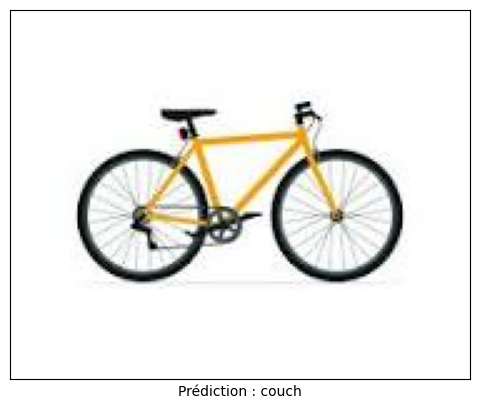

In [16]:
from PIL import Image

class_names100 = ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle',
 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle',
 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard',
 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain',
 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree',
 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket',
 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider',
 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor',
 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm']
print(len(class_names100))

def imageToArray(image_path):
  image = Image.open(image_path).convert('RGB')
  image = image.resize((32, 32))
  image_array = np.asarray(image) / 255.0
  return image_array.reshape(1, 32, 32, 3)

image_path = '/content/téléchargement.jpg'
image_array = imageToArray(image_path)
preds = model_opt.predict(image_array)
preds_single = class_names100[np.argmax(preds)]

plt.xticks([])
plt.yticks([])
plt.imshow(Image.open(image_path))
plt.xlabel(f'Prédiction : {preds_single}')
plt.show()